# PN Detection on Real MUSE Data — OIII-only Model

This notebook applies a **single-channel OIII U-Net** trained on `64×64×1` images to a real MUSE image.

Workflow:

1. Load the existing 4-channel FITS file.
2. Extract only the OIII channel.
3. Normalize OIII using the training normalization.
4. Run overlapping 64×64 tiled inference.
5. Detect PN centers from the predicted heatmap.
6. Load the PN catalogue.
7. Convert catalogue RA/Dec to image pixel coordinates using the original MUSE FITS WCS.
8. Plot random catalogue-centered OIII cutouts with:
   - **red circles** = model detections
   - **cyan +** = catalogue PN centers

> Important: `OIII_MEAN` and `OIII_STD` must match the normalization used when training the OIII-only model.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS

from tensorflow import keras
from scipy.ndimage import maximum_filter


## 1. Settings

In [5]:
# ============================================================
# PATHS
# ============================================================

MODEL_PATH = "best_PN_UNet_OIII_focal.keras"

# Your already-created 4-channel FITS:
# channel 0 = Hbeta
# channel 1 = OIII5007
# channel 2 = Halpha
# channel 3 = NII6584
FITS_4CH_PATH = "NGC253_4channel.fits"

# Original MUSE FITS, needed only for WCS
ORIGINAL_MUSE_FITS = (
    "/Users/golta/Desktop/Uni/Thesis/"
    "ADP.2025-07-06T07_52_11.876.fits"
)

CATALOG_PATH = "PN_CAT.csv"


# ============================================================
# INFERENCE SETTINGS
# ============================================================

TILE_SIZE = 64
STRIDE = 32
BATCH_SIZE = 32

# Use the best threshold measured for the OIII-only model.
PEAK_THRESHOLD = 0.20
MIN_DISTANCE = 3


# ============================================================
# OIII TRAINING NORMALIZATION
# ============================================================

# These values are the OIII entries from your previous
# four-channel normalization.
#
# IMPORTANT:
# If your OIII-only model was trained with different statistics,
# replace these with the mean/std actually used for that model.

OIII_MEAN = 1.2861429e-18
OIII_STD  = 5.3478021e-18


## 2. Load the OIII-only Keras model

In [6]:
model = keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)

expected_input = (None, TILE_SIZE, TILE_SIZE, 1)

if model.input_shape[-1] != 1:
    raise ValueError(
        f"This notebook expects an OIII-only model with 1 input channel, "
        f"but model.input_shape is {model.input_shape}"
    )


2026-09-01 20:35:38.244875: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-09-01 20:35:38.245036: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-09-01 20:35:38.245048: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1788287738.245571  139336 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1788287738.245896  139336 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model input shape : (None, 64, 64, 1)
Model output shape: (None, 64, 64, 1)


## 3. Load the 4-channel FITS and extract OIII

The stacked FITS created earlier uses:

- channel 0: Hβ
- channel 1: [O III] λ5007
- channel 2: Hα
- channel 3: [N II] λ6584

Only channel 1 is passed to the network.


In [7]:
image_4ch = fits.getdata(
    FITS_4CH_PATH
).astype(np.float64)

print("4-channel FITS shape:", image_4ch.shape)

if image_4ch.ndim != 3 or image_4ch.shape[-1] != 4:
    raise ValueError(
        f"Expected FITS shape (Ny, Nx, 4), got {image_4ch.shape}"
    )

# OIII image used for visualization
oiii_display = image_4ch[..., 1]

# Add the single channel dimension required by TensorFlow
# (Ny, Nx) -> (Ny, Nx, 1)
oiii = oiii_display[..., np.newaxis]

print("OIII display shape :", oiii_display.shape)
print("OIII network shape :", oiii.shape)


4-channel FITS shape: (1733, 6080, 4)
OIII display shape : (1733, 6080)
OIII network shape : (1733, 6080, 1)


## 4. Normalize OIII

In [8]:
# A spatial pixel is valid if the OIII value is finite.
valid_mask = np.isfinite(oiii_display)

oiii_clean = oiii.copy()

# Replacing invalid values with the training mean makes them 0
# after standardization.
bad = ~np.isfinite(oiii_clean[..., 0])
oiii_clean[..., 0][bad] = OIII_MEAN

# IMPORTANT: no '+ 1e-8' here.
oiii_norm = (
    oiii_clean - OIII_MEAN
) / OIII_STD

oiii_norm = oiii_norm.astype(np.float32)

values = oiii_norm[..., 0]

finite_values = values[np.isfinite(values)]

print("Normalized OIII statistics:")
print(f"mean = {np.mean(finite_values):.6g}")
print(f"std  = {np.std(finite_values):.6g}")
print(f"min  = {np.min(finite_values):.6g}")
print(f"max  = {np.max(finite_values):.6g}")


Normalized OIII statistics:
mean = 2.95733
std  = 8736.09
min  = -0.240499
max  = 2.831e+07


## 5. Tiled inference on the complete OIII image

In [9]:
def get_start_positions(length, tile_size, stride):
    if length <= tile_size:
        return [0]

    positions = list(
        range(
            0,
            length - tile_size + 1,
            stride
        )
    )

    final_position = length - tile_size

    if positions[-1] != final_position:
        positions.append(final_position)

    return positions


def predict_full_image(
    model,
    image,
    tile_size=64,
    stride=32,
    batch_size=32
):
    """
    Apply a fixed-size single-channel model to a full image using
    overlapping tiles and weighted blending.

    Parameters
    ----------
    model
        Keras model expecting (None, tile_size, tile_size, 1).

    image : ndarray
        Normalized image with shape (Ny, Nx, 1).
    """

    height, width, channels = image.shape

    if channels != 1:
        raise ValueError(
            f"Expected single-channel input (Ny, Nx, 1), got {image.shape}"
        )

    # --------------------------------------------------------
    # Pad if image is smaller than one model tile
    # --------------------------------------------------------
    pad_y = max(0, tile_size - height)
    pad_x = max(0, tile_size - width)

    if pad_y > 0 or pad_x > 0:
        image_padded = np.pad(
            image,
            (
                (0, pad_y),
                (0, pad_x),
                (0, 0)
            ),
            mode="edge"
        )
    else:
        image_padded = image

    padded_height, padded_width, _ = image_padded.shape

    y_positions = get_start_positions(
        padded_height,
        tile_size,
        stride
    )

    x_positions = get_start_positions(
        padded_width,
        tile_size,
        stride
    )

    coordinates = [
        (y, x)
        for y in y_positions
        for x in x_positions
    ]

    print("Number of inference tiles:", len(coordinates))

    prediction_sum = np.zeros(
        (padded_height, padded_width),
        dtype=np.float32
    )

    weight_sum = np.zeros(
        (padded_height, padded_width),
        dtype=np.float32
    )

    # Down-weight tile boundaries to reduce stitching artifacts.
    w = np.hanning(tile_size).astype(np.float32)
    weight = np.outer(w, w)

    # Hann is exactly 0 at the boundary, so retain a minimum weight.
    weight = 0.1 + 0.9 * weight

    for start in range(0, len(coordinates), batch_size):

        batch_coords = coordinates[
            start:start + batch_size
        ]

        batch = np.stack([
            image_padded[
                y:y + tile_size,
                x:x + tile_size,
                :
            ]
            for y, x in batch_coords
        ])

        # shape: (B, 64, 64, 1)
        batch_predictions = model.predict(
            batch,
            verbose=0
        )

        if batch_predictions.ndim != 4 or batch_predictions.shape[-1] != 1:
            raise ValueError(
                f"Expected model output (B, H, W, 1), got "
                f"{batch_predictions.shape}"
            )

        batch_predictions = batch_predictions[..., 0]

        for (y, x), pred in zip(
            batch_coords,
            batch_predictions
        ):
            prediction_sum[
                y:y + tile_size,
                x:x + tile_size
            ] += pred * weight

            weight_sum[
                y:y + tile_size,
                x:x + tile_size
            ] += weight

    full_prediction = (
        prediction_sum
        / np.maximum(weight_sum, 1e-12)
    )

    return full_prediction[
        :height,
        :width
    ]


In [10]:
pn_heatmap = predict_full_image(
    model=model,
    image=oiii_norm,
    tile_size=TILE_SIZE,
    stride=STRIDE,
    batch_size=BATCH_SIZE
)

# Ignore invalid regions in the original OIII map.
pn_heatmap[~valid_mask] = 0.0

print("PN heatmap shape:", pn_heatmap.shape)
print("Prediction min   :", np.nanmin(pn_heatmap))
print("Prediction max   :", np.nanmax(pn_heatmap))


Number of inference tiles: 10206


2026-09-01 20:35:39.505396: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


PN heatmap shape: (1733, 6080)
Prediction min   : 0.0
Prediction max   : 1.0


## 6. Detect PN centers from the heatmap

In [11]:
def find_pn_centers(
    heatmap,
    threshold=0.20,
    min_distance=3
):
    size = 2 * min_distance + 1

    local_max = (
        heatmap
        == maximum_filter(
            heatmap,
            size=size,
            mode="constant"
        )
    )

    detected = (
        local_max
        & (heatmap >= threshold)
    )

    y, x = np.where(detected)
    scores = heatmap[y, x]

    order = np.argsort(scores)[::-1]

    return np.column_stack([
        x[order],
        y[order],
        scores[order]
    ])


detections = find_pn_centers(
    pn_heatmap,
    threshold=PEAK_THRESHOLD,
    min_distance=MIN_DISTANCE
)

print("Number of PN candidates:", len(detections))
print("Columns: x, y, score")
print(detections[:20])


Number of PN candidates: 10048
Columns: x, y, score
[[4.09700000e+03 1.42000000e+03 1.00000000e+00]
 [3.78800000e+03 6.89000000e+02 9.99998987e-01]
 [4.09300000e+03 1.41700000e+03 9.97881114e-01]
 [4.09500000e+03 1.41300000e+03 9.83811438e-01]
 [2.56400000e+03 3.30000000e+02 8.63884151e-01]
 [1.81800000e+03 1.12000000e+02 8.15883875e-01]
 [2.46400000e+03 8.53000000e+02 6.96719468e-01]
 [2.56200000e+03 3.26000000e+02 5.40297508e-01]
 [4.15100000e+03 4.22000000e+02 5.15949488e-01]
 [1.75100000e+03 3.75000000e+02 4.73434746e-01]
 [1.60100000e+03 1.30900000e+03 4.71253872e-01]
 [4.21300000e+03 9.21000000e+02 4.67924654e-01]
 [2.52000000e+02 8.89000000e+02 4.67254698e-01]
 [4.55000000e+02 6.53000000e+02 4.64537919e-01]
 [2.31300000e+03 5.63000000e+02 4.62398231e-01]
 [2.34900000e+03 1.26300000e+03 4.59046096e-01]
 [4.66000000e+03 5.95000000e+02 4.58463520e-01]
 [2.69200000e+03 9.85000000e+02 4.58356678e-01]
 [4.00000000e+00 7.16000000e+02 4.58060026e-01]
 [1.59400000e+03 6.27000000e+02 4.57

## 7. Load the PN catalogue and convert RA/Dec to pixel coordinates

The 4-channel FITS generated with `fits.writeto(...)` does not preserve the original MUSE WCS, so the WCS is read from the original `OIII5006_FLUX` extension.


In [12]:
pn_catalog = pd.read_csv(CATALOG_PATH)

print("Catalogue columns:")
print(list(pn_catalog.columns))

print("\nNumber of catalogue PNe:", len(pn_catalog))
display(pn_catalog.head())


Catalogue columns:
['ID', 'RAdeg', 'DEdeg', 'FWHM', 'log_OIII_Hb', 'log_NII_Ha', 'log_SII_Ha', 'use_NII', 'use_SII']

Number of catalogue PNe: 571


,ID,RAdeg,DEdeg,FWHM,log_OIII_Hb,log_NII_Ha,log_SII_Ha,use_NII,use_SII
0,1,11.987615,-25.221952,0.956,1.871572,0.028113,-1.241971,False,False
1,2,11.994759,-25.220211,0.923,1.776825,-0.548196,-1.497087,False,False
2,3,12.021884,-25.194207,0.786,1.073425,-0.153119,-2.029765,True,False
3,4,11.992403,-25.218152,1.080,1.436248,-0.857334,-0.846140,False,False
4,5,11.990650,-25.220049,1.083,1.405052,-0.738616,-0.659834,False,False


In [13]:
with fits.open(ORIGINAL_MUSE_FITS) as hdul:
    oiii_header = hdul["OIII5006_FLUX"].header.copy()

wcs = WCS(oiii_header).celestial

ra = pn_catalog["RAdeg"].to_numpy()
dec = pn_catalog["DEdeg"].to_numpy()

catalog_x, catalog_y = wcs.world_to_pixel_values(
    ra,
    dec
)

pn_catalog["x"] = catalog_x
pn_catalog["y"] = catalog_y

display(
    pn_catalog[
        ["ID", "RAdeg", "DEdeg", "x", "y"]
    ].head()
)


,ID,RAdeg,DEdeg,x,y
0,1,11.987615,-25.221952,1048.627172,768.130699
1,2,11.994759,-25.220211,938.519031,719.198444
2,3,12.021884,-25.194207,300.579898,804.410077
3,4,11.992403,-25.218152,944.981903,772.147353
4,5,11.990650,-25.220049,988.645826,763.612216


## 8. Keep only catalogue PNe inside the OIII image

In [14]:
height, width = oiii_display.shape

inside_image = (
    np.isfinite(pn_catalog["x"])
    & np.isfinite(pn_catalog["y"])
    & (pn_catalog["x"] >= 0)
    & (pn_catalog["x"] < width)
    & (pn_catalog["y"] >= 0)
    & (pn_catalog["y"] < height)
)

catalog_in_image = pn_catalog[
    inside_image
].copy()

print(
    f"Catalogue PNe inside image: "
    f"{len(catalog_in_image)} / {len(pn_catalog)}"
)


Catalogue PNe inside image: 571 / 571


## 9. Plot catalogue-centered OIII cutouts with model predictions

- **cyan +** = catalogue PN center
- **red circle** = model-detected PN center
- Top row: OIII flux image
- Bottom row: model prediction heatmap


In [15]:
def plot_catalog_pn_cutouts(
    oiii,
    pn_heatmap,
    detections,
    catalog,
    n_cutouts=8,
    cutout_size=64,
    seed=42,
    threshold=0.20,
    lower_percentile=8,
    upper_percentile=99
):
    rng = np.random.default_rng(seed)

    height, width = oiii.shape

    if len(catalog) == 0:
        print("No catalogue PNe fall inside the image.")
        return

    n = min(n_cutouts, len(catalog))

    selected_indices = rng.choice(
        len(catalog),
        size=n,
        replace=False
    )

    selected = catalog.iloc[selected_indices]

    fig, axes = plt.subplots(
        2,
        n,
        figsize=(4 * n, 8),
        squeeze=False
    )

    half = cutout_size // 2

    for i, (_, pn) in enumerate(selected.iterrows()):

        xc = float(pn["x"])
        yc = float(pn["y"])

        # ----------------------------------------------------
        # Construct cutout around catalogue PN
        # ----------------------------------------------------
        x0 = int(round(xc)) - half
        y0 = int(round(yc)) - half

        x0 = max(
            0,
            min(
                x0,
                max(0, width - cutout_size)
            )
        )

        y0 = max(
            0,
            min(
                y0,
                max(0, height - cutout_size)
            )
        )

        x1 = min(x0 + cutout_size, width)
        y1 = min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]

        # Catalogue center in local cutout coordinates
        cat_x = xc - x0
        cat_y = yc - y0

        # ----------------------------------------------------
        # Model detections in this cutout
        # ----------------------------------------------------
        inside = (
            (detections[:, 0] >= x0)
            & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0)
            & (detections[:, 1] < y1)
            & (detections[:, 2] >= threshold)
        )

        det = detections[inside]

        model_x = det[:, 0] - x0
        model_y = det[:, 1] - y0

        # ----------------------------------------------------
        # OIII display scaling
        # ----------------------------------------------------
        finite = oiii_cutout[np.isfinite(oiii_cutout)]

        if len(finite) > 0:
            vmin = np.percentile(
                finite,
                lower_percentile
            )
            vmax = np.percentile(
                finite,
                upper_percentile
            )

            if vmax <= vmin:
                vmax = vmin + 1.0
        else:
            vmin, vmax = 0, 1

        # ====================================================
        # TOP: OIII
        # ====================================================
        ax = axes[0, i]

        ax.imshow(
            oiii_cutout,
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        # Catalogue center
        ax.scatter(
            cat_x,
            cat_y,
            marker="+",
            s=180,
            linewidths=2.5,
            c="cyan",
            label="Catalogue"
        )

        # Model detections
        if len(det) > 0:
            ax.scatter(
                model_x,
                model_y,
                facecolors="none",
                edgecolors="red",
                s=120,
                linewidths=2,
                label="Model"
            )

        pn_id = pn["ID"]
        ax.set_title(
            f"PN {pn_id}\n"
            f"{len(det)} model candidate(s)"
        )

        if i == 0:
            ax.legend(loc="upper right")

        # ====================================================
        # BOTTOM: MODEL HEATMAP
        # ====================================================
        ax = axes[1, i]

        ax.imshow(
            pred_cutout,
            origin="lower",
            vmin=0,
            vmax=1
        )

        ax.scatter(
            cat_x,
            cat_y,
            marker="+",
            s=180,
            linewidths=2.5,
            c="cyan"
        )

        if len(det) > 0:
            ax.scatter(
                model_x,
                model_y,
                facecolors="none",
                edgecolors="red",
                s=120,
                linewidths=2
            )

        ax.set_title("PN prediction")

    axes[0, 0].set_ylabel("OIII")
    axes[1, 0].set_ylabel("Prediction")

    plt.tight_layout()
    plt.show()


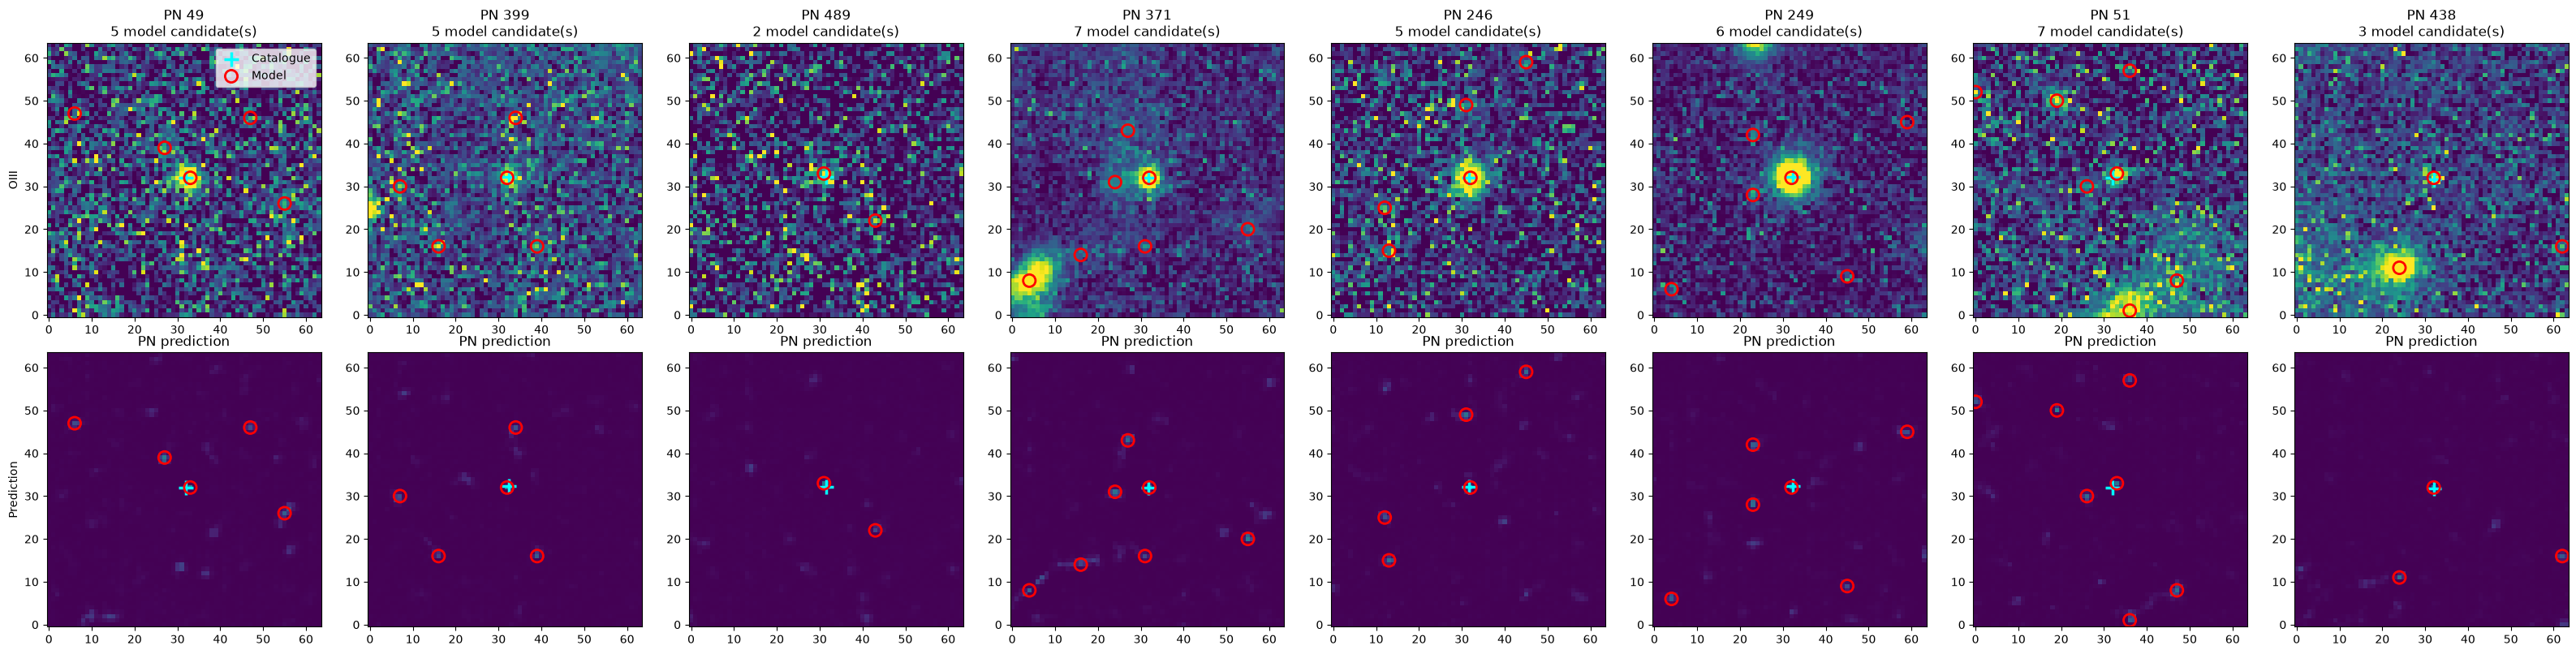

In [16]:
plot_catalog_pn_cutouts(
    oiii=oiii_display,
    pn_heatmap=pn_heatmap,
    detections=detections,
    catalog=catalog_in_image,
    n_cutouts=8,
    cutout_size=64,
    seed=42,
    threshold=PEAK_THRESHOLD
)


## 10. Optional: inspect random model detections instead of random catalogue PNe

This is useful for visually checking likely false positives. Each cutout is centered on one model detection, while catalogue PN positions falling inside the same cutout are overlaid.


In [17]:
def plot_model_detection_cutouts(
    oiii,
    pn_heatmap,
    detections,
    catalog,
    n_cutouts=8,
    cutout_size=64,
    seed=42
):
    if len(detections) == 0:
        print("No model detections available.")
        return

    rng = np.random.default_rng(seed)

    height, width = oiii.shape
    n = min(n_cutouts, len(detections))

    chosen = rng.choice(
        len(detections),
        size=n,
        replace=False
    )

    selected = detections[chosen]

    fig, axes = plt.subplots(
        2,
        n,
        figsize=(4 * n, 8),
        squeeze=False
    )

    half = cutout_size // 2

    for i, (xc, yc, score) in enumerate(selected):

        x0 = int(round(xc)) - half
        y0 = int(round(yc)) - half

        x0 = max(0, min(x0, max(0, width - cutout_size)))
        y0 = max(0, min(y0, max(0, height - cutout_size)))

        x1 = min(x0 + cutout_size, width)
        y1 = min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]

        local_model_x = xc - x0
        local_model_y = yc - y0

        cat_inside = (
            (catalog["x"] >= x0)
            & (catalog["x"] < x1)
            & (catalog["y"] >= y0)
            & (catalog["y"] < y1)
        )

        cat_cut = catalog[cat_inside]

        cat_x = cat_cut["x"].to_numpy() - x0
        cat_y = cat_cut["y"].to_numpy() - y0

        finite = oiii_cutout[np.isfinite(oiii_cutout)]

        if len(finite):
            vmin = np.percentile(finite, 8)
            vmax = np.percentile(finite, 99)
            if vmax <= vmin:
                vmax = vmin + 1.0
        else:
            vmin, vmax = 0, 1

        axes[0, i].imshow(
            oiii_cutout,
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        axes[0, i].scatter(
            local_model_x,
            local_model_y,
            facecolors="none",
            edgecolors="red",
            s=140,
            linewidths=2
        )

        if len(cat_cut):
            axes[0, i].scatter(
                cat_x,
                cat_y,
                marker="+",
                c="cyan",
                s=180,
                linewidths=2.5
            )

        axes[0, i].set_title(
            f"Model score = {score:.3f}\n"
            f"{len(cat_cut)} catalogue PN(s)"
        )

        axes[1, i].imshow(
            pred_cutout,
            origin="lower",
            vmin=0,
            vmax=1
        )

        axes[1, i].scatter(
            local_model_x,
            local_model_y,
            facecolors="none",
            edgecolors="red",
            s=140,
            linewidths=2
        )

        if len(cat_cut):
            axes[1, i].scatter(
                cat_x,
                cat_y,
                marker="+",
                c="cyan",
                s=180,
                linewidths=2.5
            )

        axes[1, i].set_title("PN prediction")

    plt.tight_layout()
    plt.show()


# Uncomment to use:
#
# plot_model_detection_cutouts(
#     oiii=oiii_display,
#     pn_heatmap=pn_heatmap,
#     detections=detections,
#     catalog=catalog_in_image,
#     n_cutouts=8,
#     cutout_size=64,
#     seed=42
# )
